In [498]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
import math
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV







## Étape 1 — Chargement et Analyse exploratoire des données 


#### comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;

In [499]:
df=pd.read_csv("../data/student_mental_health.csv")

In [500]:
# Dimensions
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Informations generales
df.info()

# Types de donnees
display(df.dtypes)


Nombre de lignes : 2000
Nombre de colonnes : 17
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 1

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

### Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 


In [501]:
print("Nombre de doublons :", df.duplicated().sum())
print("Nombre de manquantes :", df.isnull().sum())


Nombre de doublons : 0
Nombre de manquantes : Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [502]:
print(df[df.duplicated()])

Empty DataFrame
Columns: [Student_ID, Age, Gender, Year_of_Study, Sleep_Hours, Study_Hours_Per_Week, GPA, Social_Media_Hours, Screen_Time_Hours, Physical_Activity, Financial_Stress, Family_Support, Attendance_Rate, Part_Time_Job, Diet_Quality, Previous_Mental_Health_History, Mental_Health_Risk]
Index: []


### Produire des statistiques descriptives.

In [503]:
# Statistiques des variables numeriques
display(df.describe())

# Valeurs uniques des variables categorielles
categorial=df.select_dtypes(include="object").columns
for col in categorial:
    print(f"\n{col}:")
    print(df[col].value_counts())

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000



Student_ID:
Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64

Gender:
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity:
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job:
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality:
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Previous_Mental_Health_History:
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk:
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


C:\Users\Youcode\AppData\Local\Temp\ipykernel_11996\3443660404.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorial=df.select_dtypes(include="object").columns


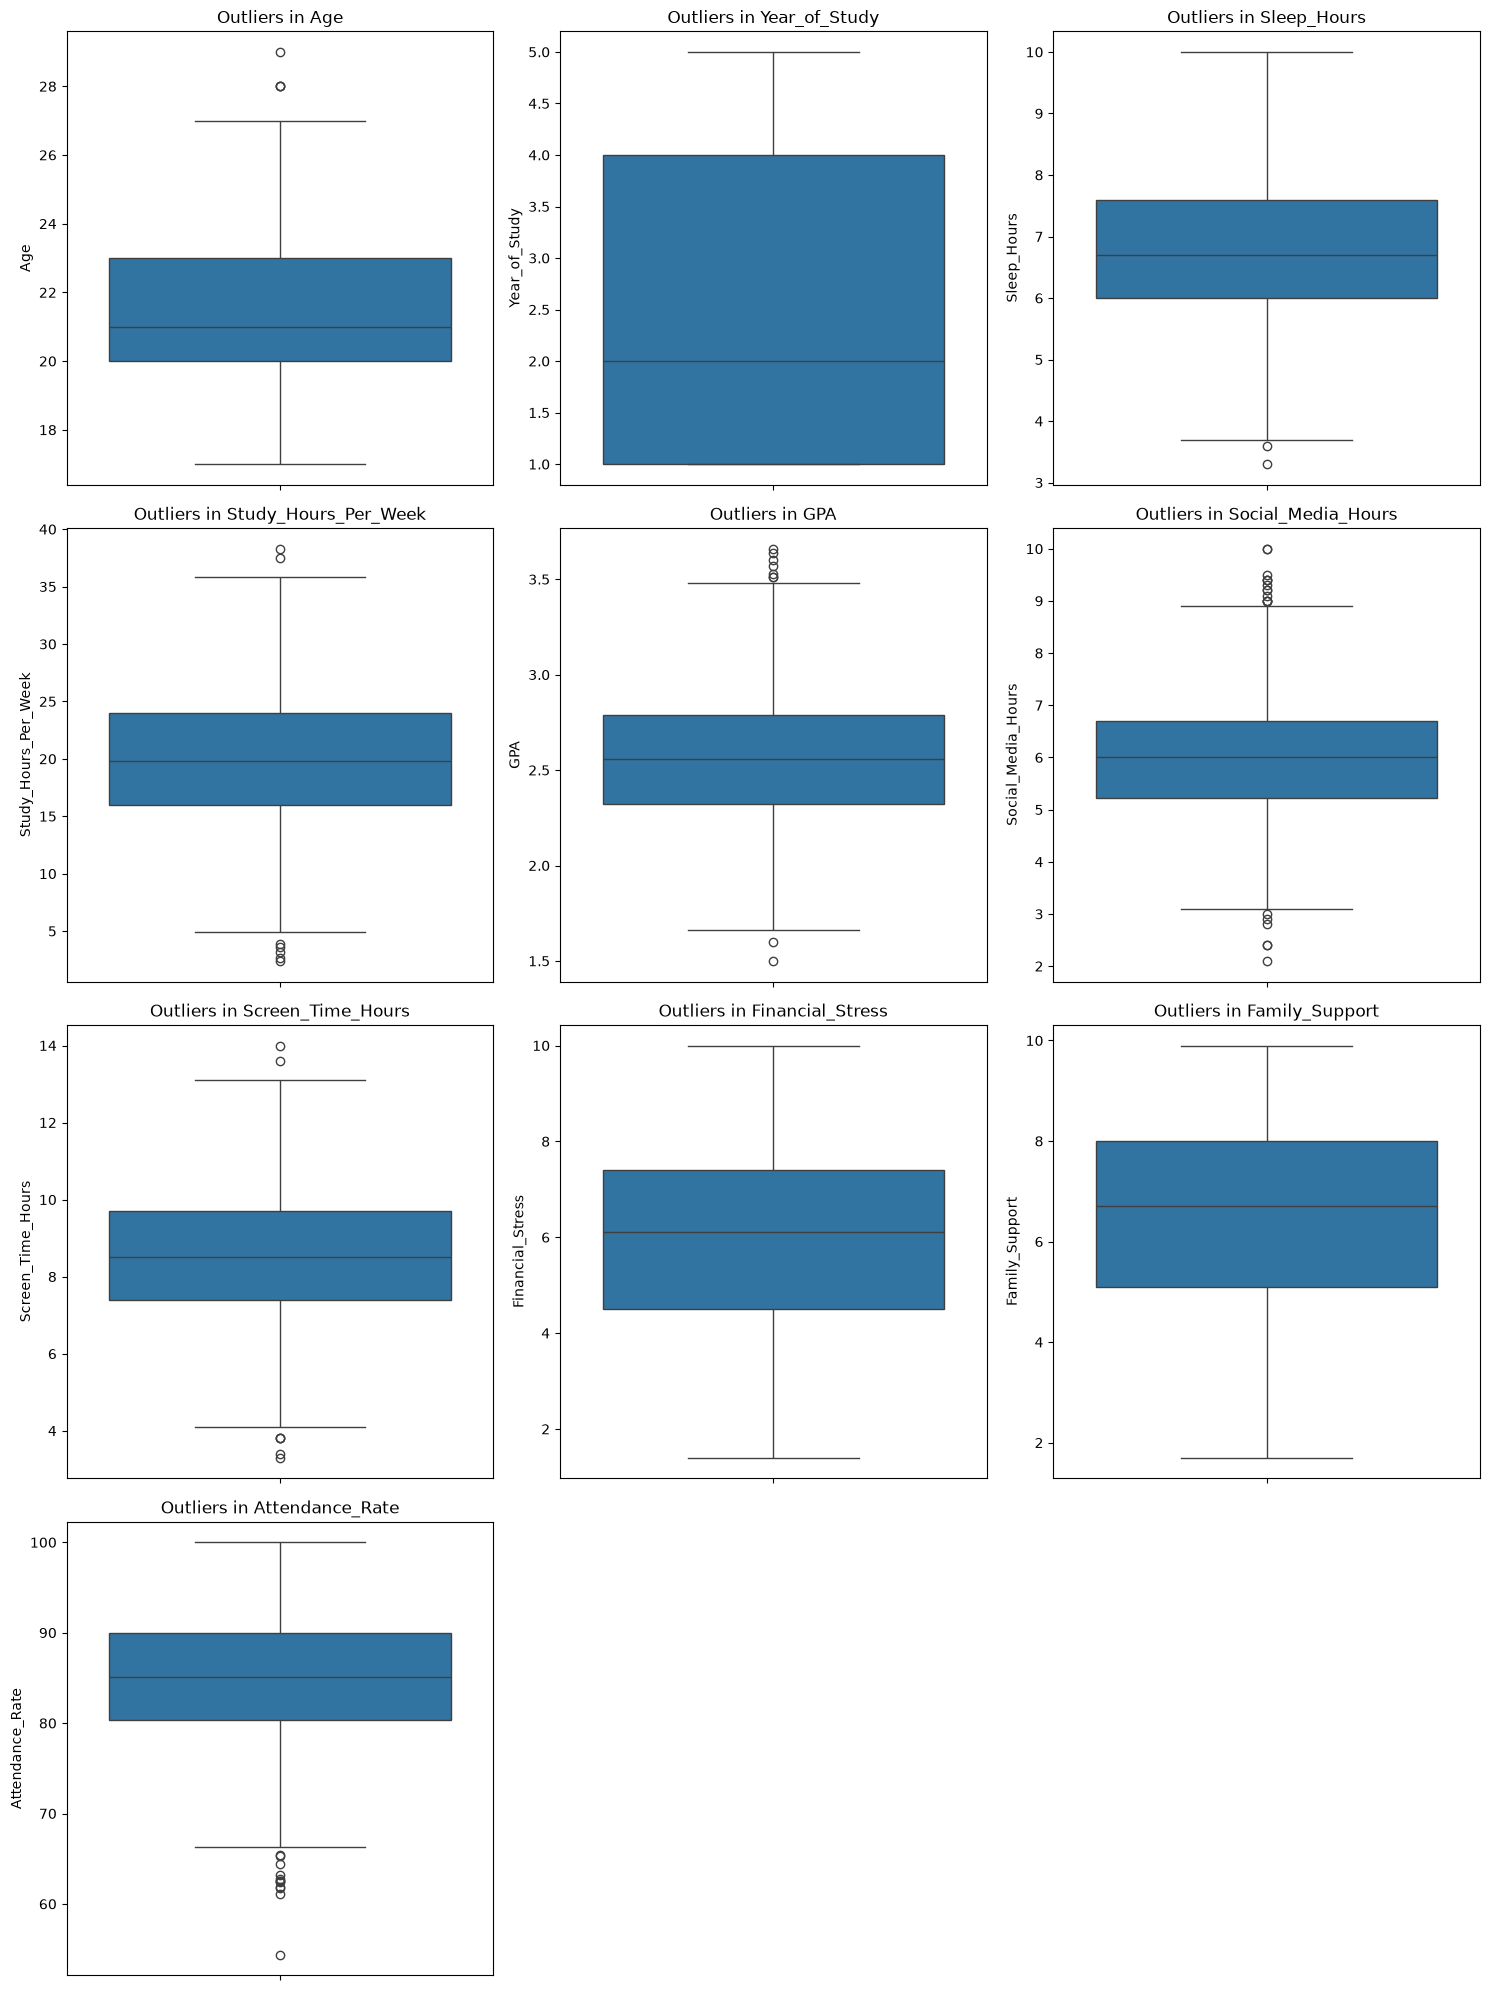

In [504]:
numeric_cols = df.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(15, 5 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()

### Étudier la distribution de la variable cible et l’éventuel déséquilibre des classes.

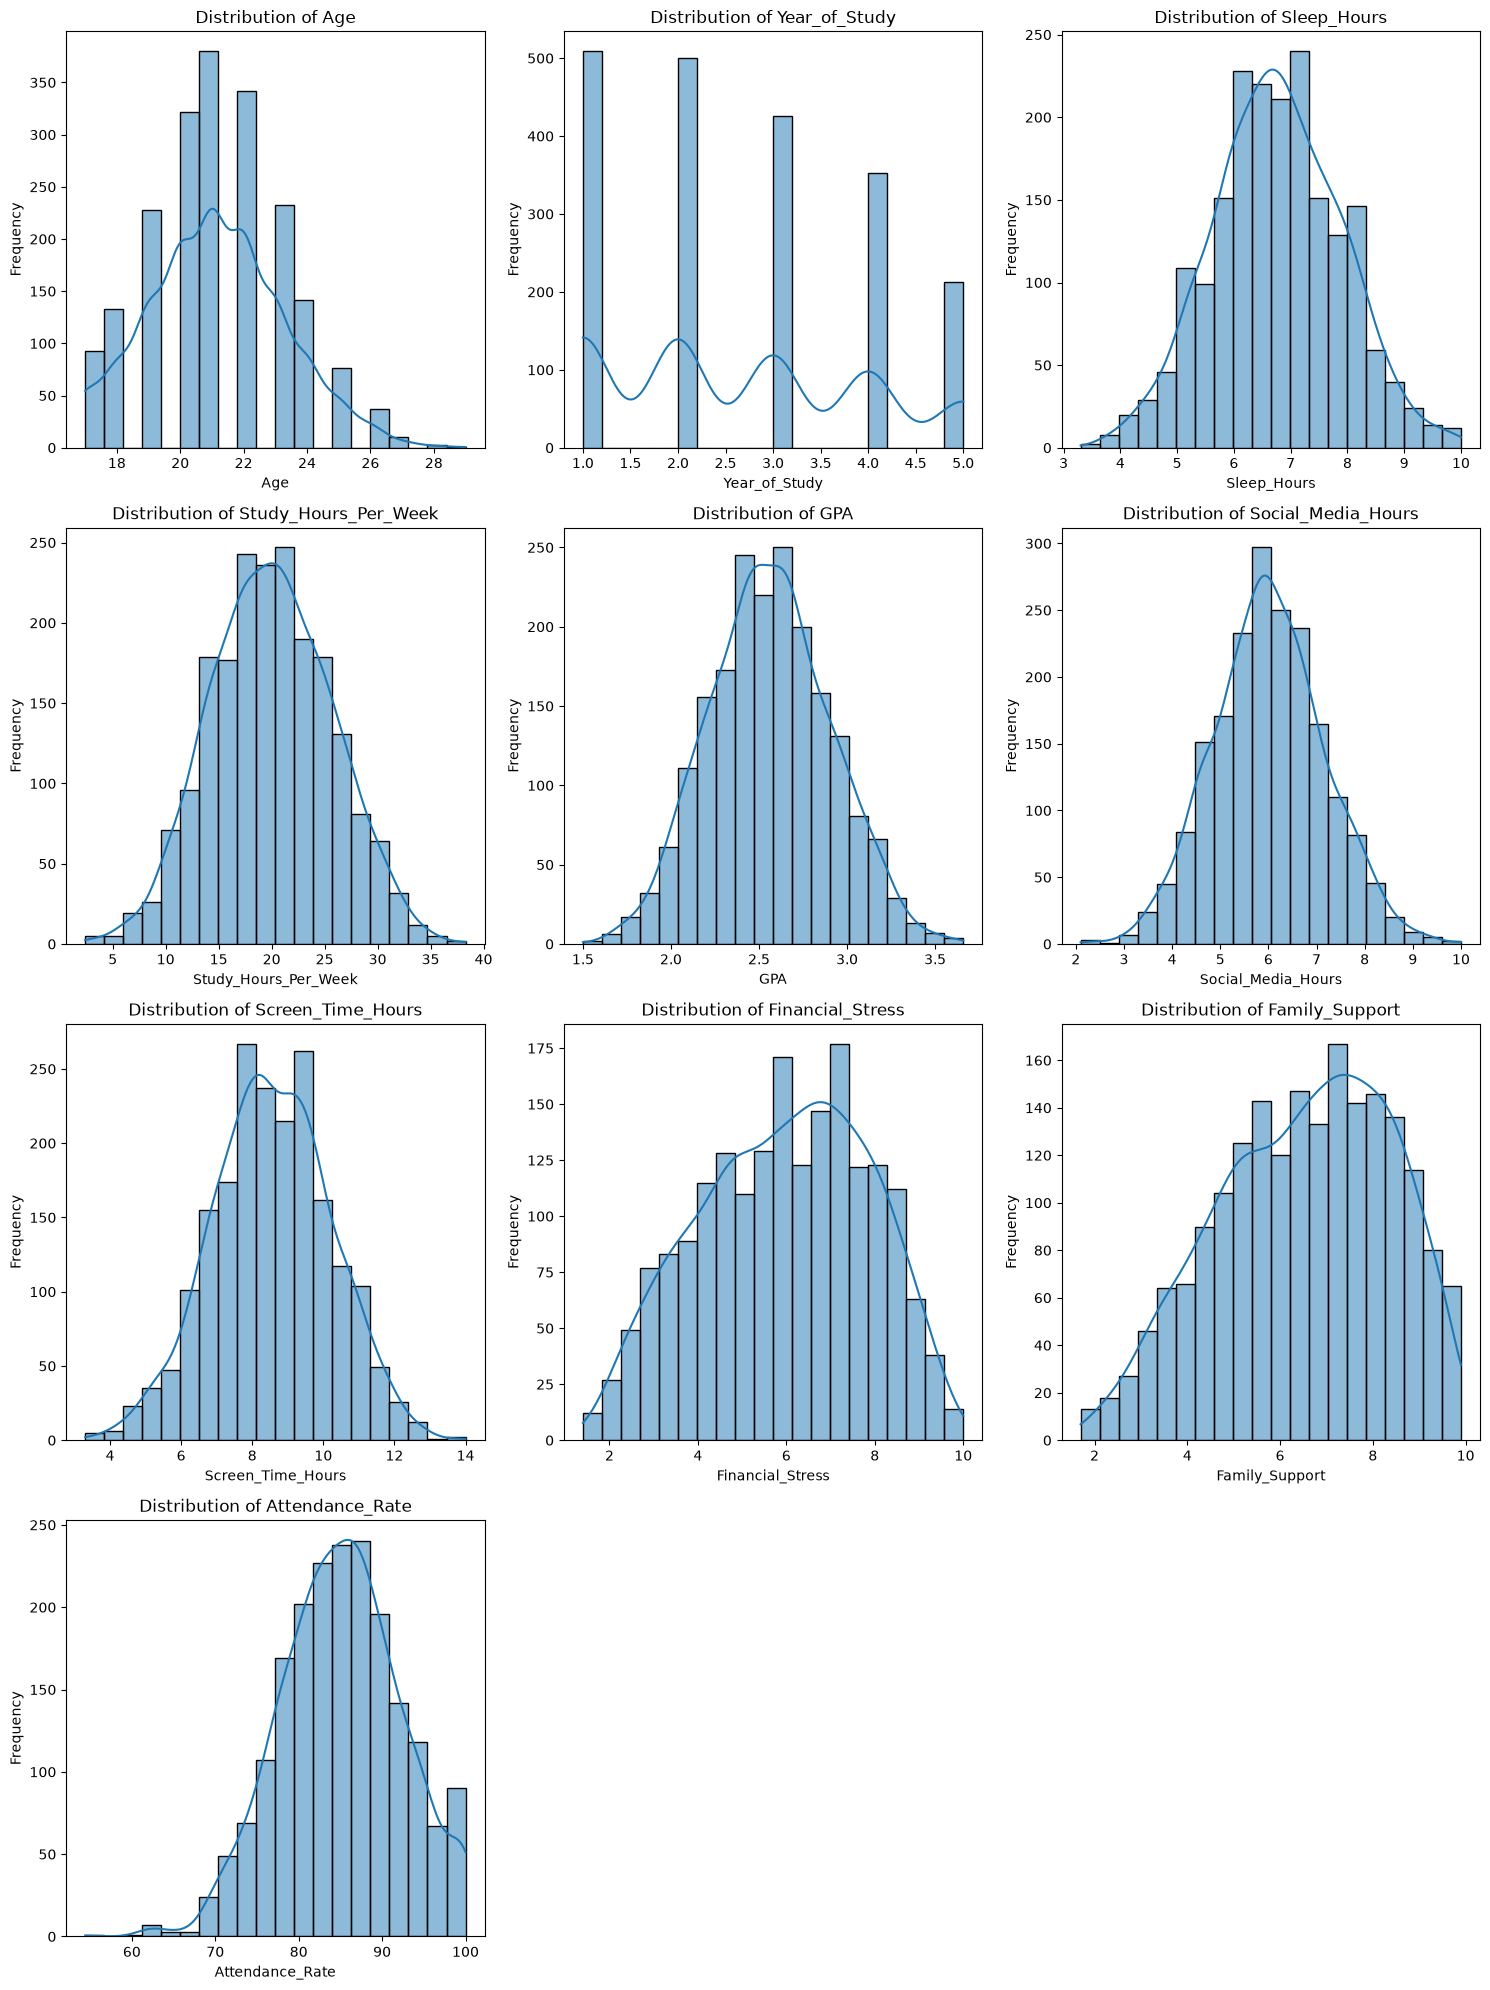

In [505]:
numeric_cols = df.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(15, 5 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(data=df, x=col, kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [506]:
result = df[
    df["Social_Media_Hours"] > df["Screen_Time_Hours"]
]
print(len(result))
print(result[
    ["Social_Media_Hours", "Screen_Time_Hours"]
])

37
      Social_Media_Hours  Screen_Time_Hours
78                   5.0                4.9
168                  5.6                5.3
209                  7.5                7.3
278                  6.0                5.1
382                  5.3                4.1
424                  5.5                4.4
476                  5.5                5.3
505                  5.6                5.5
557                  4.6                4.4
588                  5.7                5.3
628                  4.9                4.6
641                  5.4                4.8
718                  6.2                5.9
758                  7.1                6.1
784                  7.9                6.9
942                  5.8                5.7
951                  5.4                5.2
956                  6.2                5.6
962                  7.0                6.3
980                  5.9                5.5
1166                 6.8                5.9
1169                 3.9     

In [507]:
# Select numerical columns
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Count outliers
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers\n")
    print(outliers[col].to_list())

Age : 4 outliers

[29, 28, 28, 28]
Year_of_Study : 0 outliers

[]
Sleep_Hours : 2 outliers

[3.6, 3.3]
Study_Hours_Per_Week : 7 outliers

[3.9, 3.2, 3.6, 38.3, 2.4, 37.5, 2.7]
GPA : 9 outliers

[3.6, 1.5, 3.66, 3.53, 3.64, 3.57, 3.51, 1.6, 3.51]
Social_Media_Hours : 20 outliers

[2.4, 9.0, 2.8, 2.1, 9.4, 3.0, 10.0, 9.0, 2.9, 9.1, 9.0, 2.4, 9.4, 9.0, 10.0, 9.3, 9.4, 9.2, 9.5, 9.2]
Screen_Time_Hours : 7 outliers

[3.4, 3.8, 3.8, 3.3, 3.8, 13.6, 14.0]
Financial_Stress : 0 outliers

[]
Family_Support : 0 outliers

[]
Attendance_Rate : 12 outliers

[61.1, 62.4, 62.5, 62.8, 62.5, 63.2, 65.4, 65.3, 54.4, 61.8, 64.4, 61.9]


In [508]:
# Variables numériques
print(df[numeric_cols].describe())

# Variables catégorielles
print(df[categorial].describe())

               Age  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
count  2000.000000    2000.000000  1938.000000           2000.000000   
mean     21.131500       2.630000     6.758875             19.997900   
std       2.139275       1.316802     1.127072              5.719274   
min      17.000000       1.000000     3.300000              2.400000   
25%      20.000000       1.000000     6.000000             16.000000   
50%      21.000000       2.000000     6.700000             19.800000   
75%      23.000000       4.000000     7.600000             24.000000   
max      29.000000       5.000000    10.000000             38.300000   

               GPA  Social_Media_Hours  Screen_Time_Hours  Financial_Stress  \
count  1962.000000         1942.000000        2000.000000       1909.000000   
mean      2.562503            6.013955           8.548500          5.956260   
std       0.343993            1.153422           1.657571          1.893941   
min       1.500000            2.100

In [509]:
# Fréquence de chaque classe
print(df["Mental_Health_Risk"].value_counts())
print("\n")
# Pourcentage de chaque classe
print(df["Mental_Health_Risk"].value_counts(normalize=True) * 100)

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


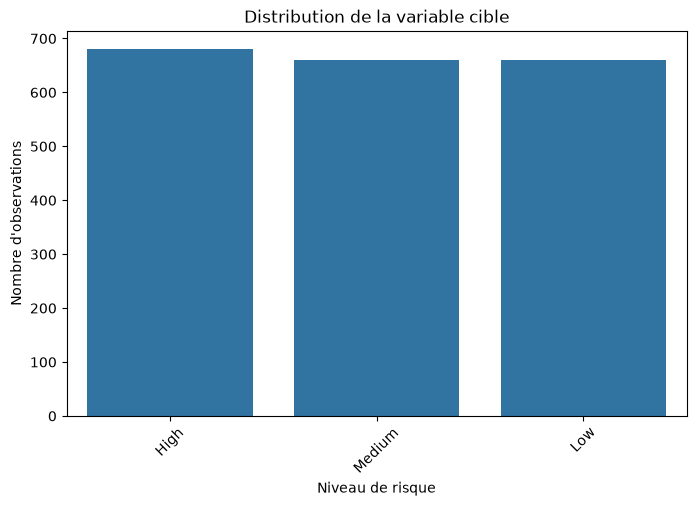

In [510]:
plt.figure(figsize=(8, 5))

sns.countplot(x=df["Mental_Health_Risk"])

plt.title("Distribution de la variable cible")
plt.xlabel("Niveau de risque")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45)
plt.show()

### Analyser les relations entre les variables explicatives et la cible.

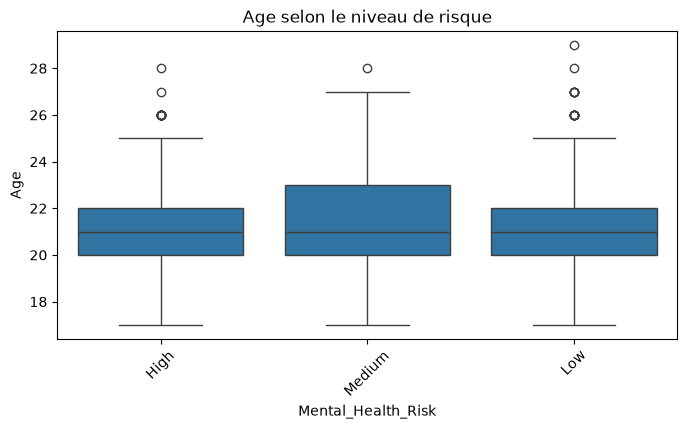

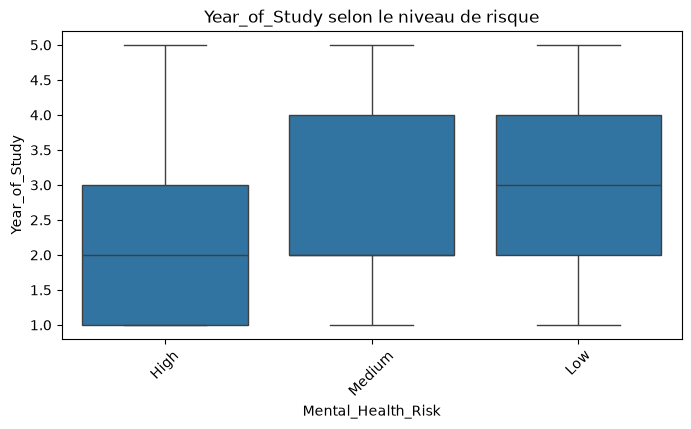

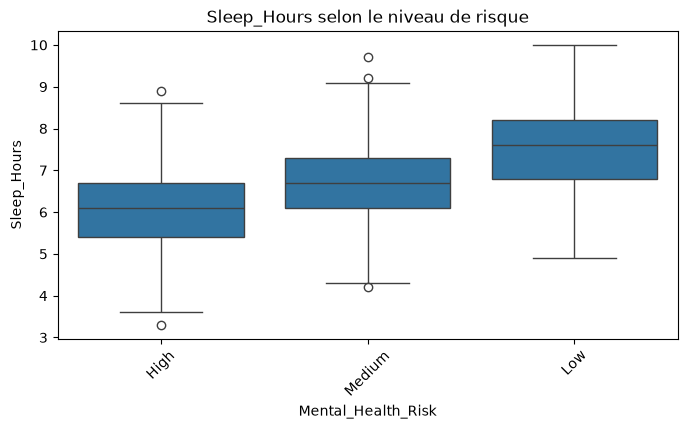

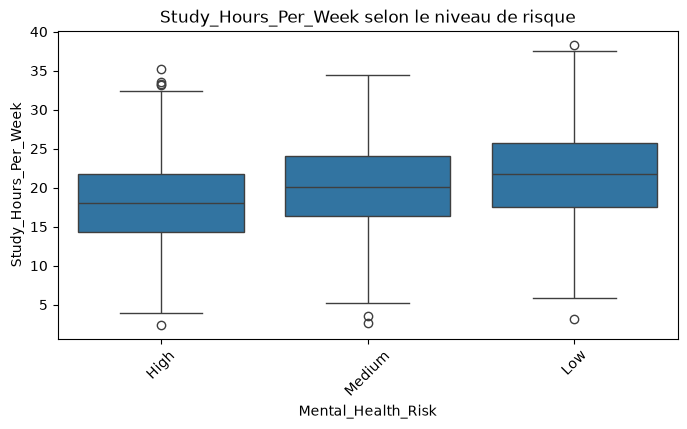

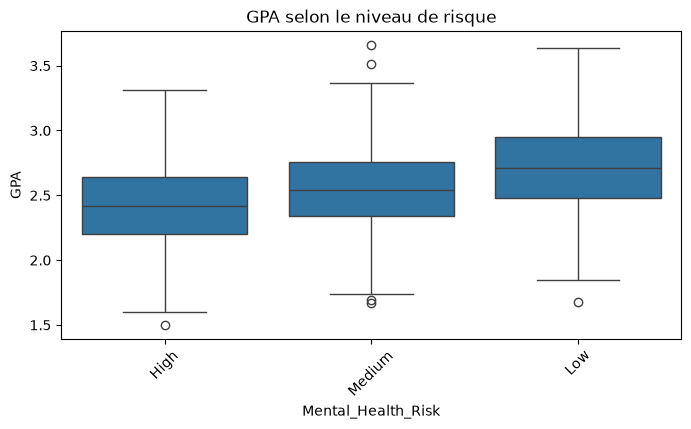

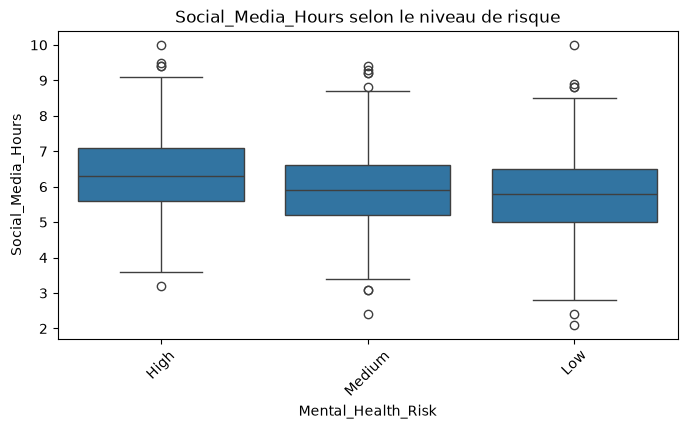

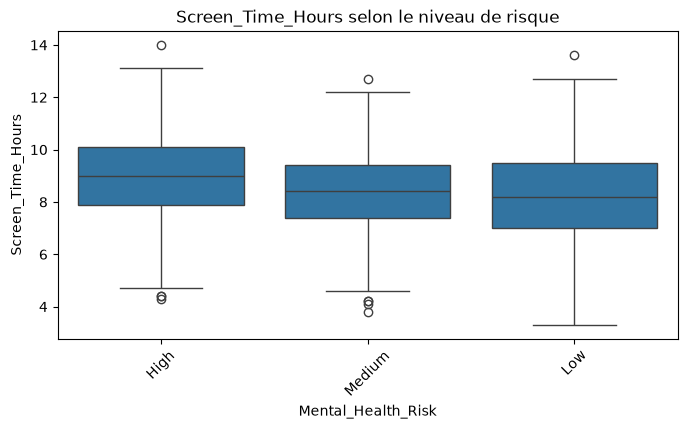

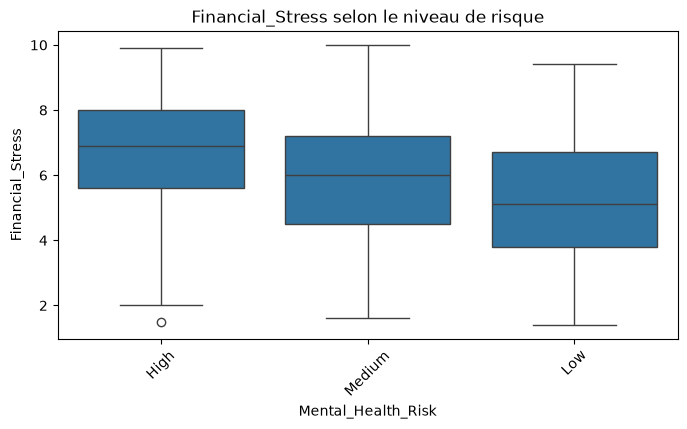

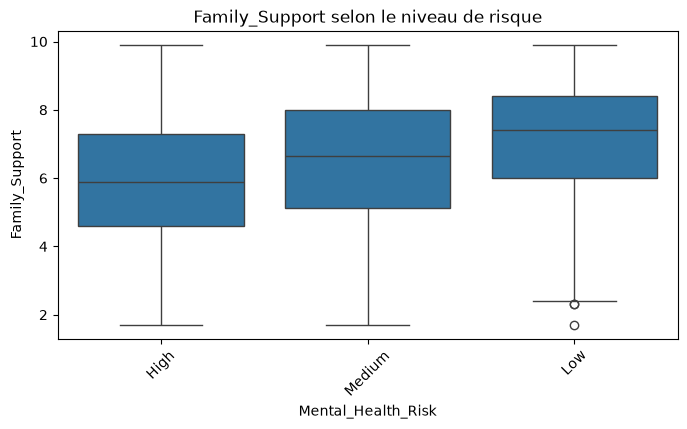

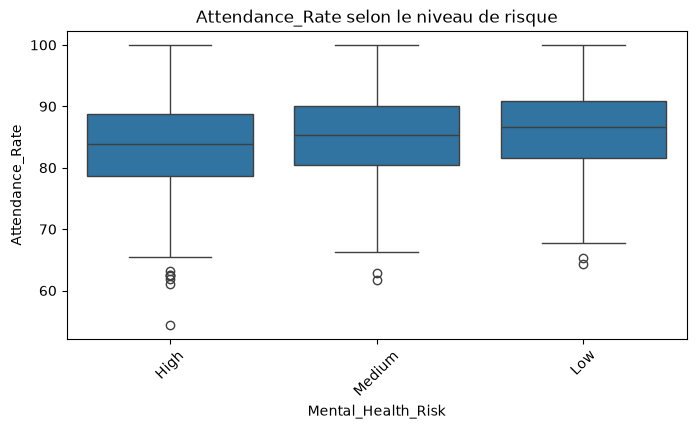

In [511]:
target_col="Mental_Health_Risk"
# the target with the numeric columns
for col in numeric_cols:
    if col != target_col:
        plt.figure(figsize=(8, 4))

        sns.boxplot(data=df, x=target_col, y=col)

        plt.title(f"{col} selon le niveau de risque")
        plt.xticks(rotation=45)
        plt.show()

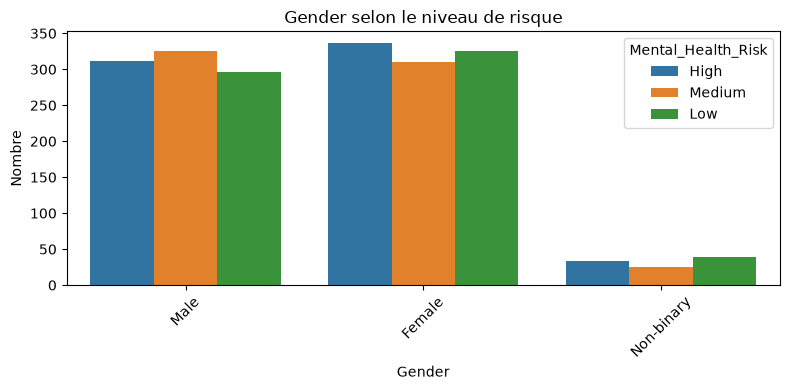

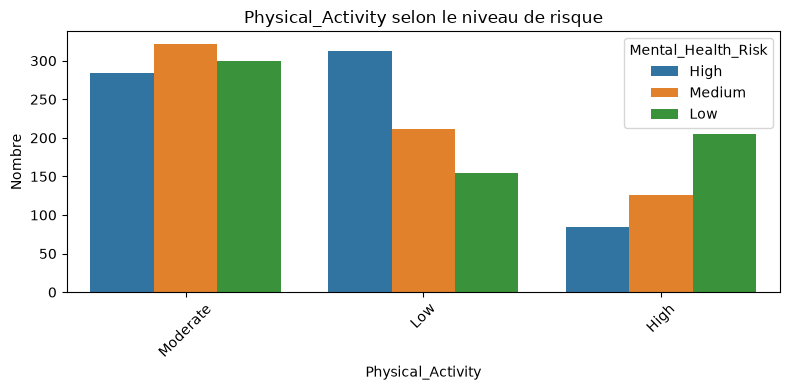

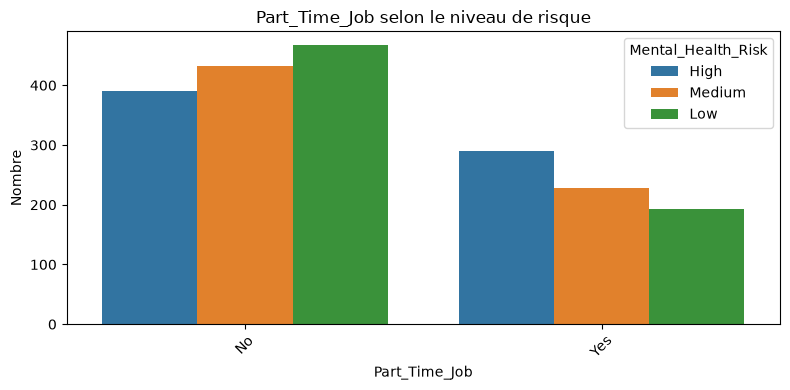

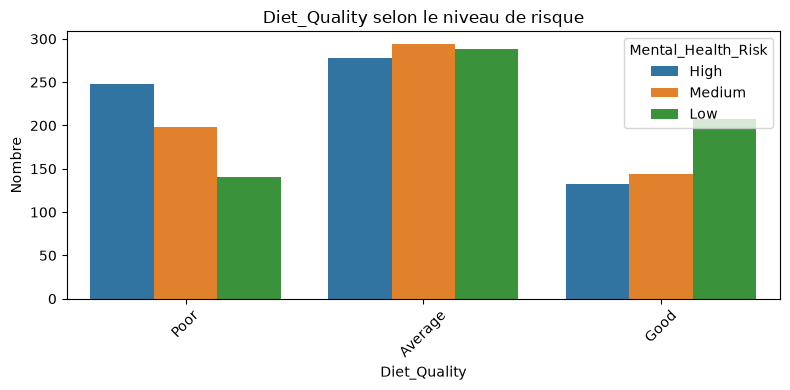

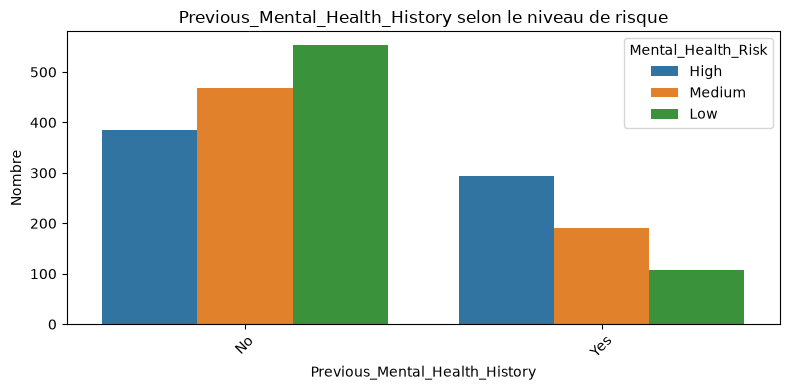

In [512]:
for col in categorial:
    if col != target_col and col != "Student_ID":

        plt.figure(figsize=(8, 4))

        sns.countplot(data=df, x=col, hue=target_col)

        plt.title(f"{col} selon le niveau de risque")
        plt.xlabel(col)
        plt.ylabel("Nombre")
        plt.xticks(rotation=45)

        plt.tight_layout()
        plt.show()

### Examiner les corrélations entre les variables.

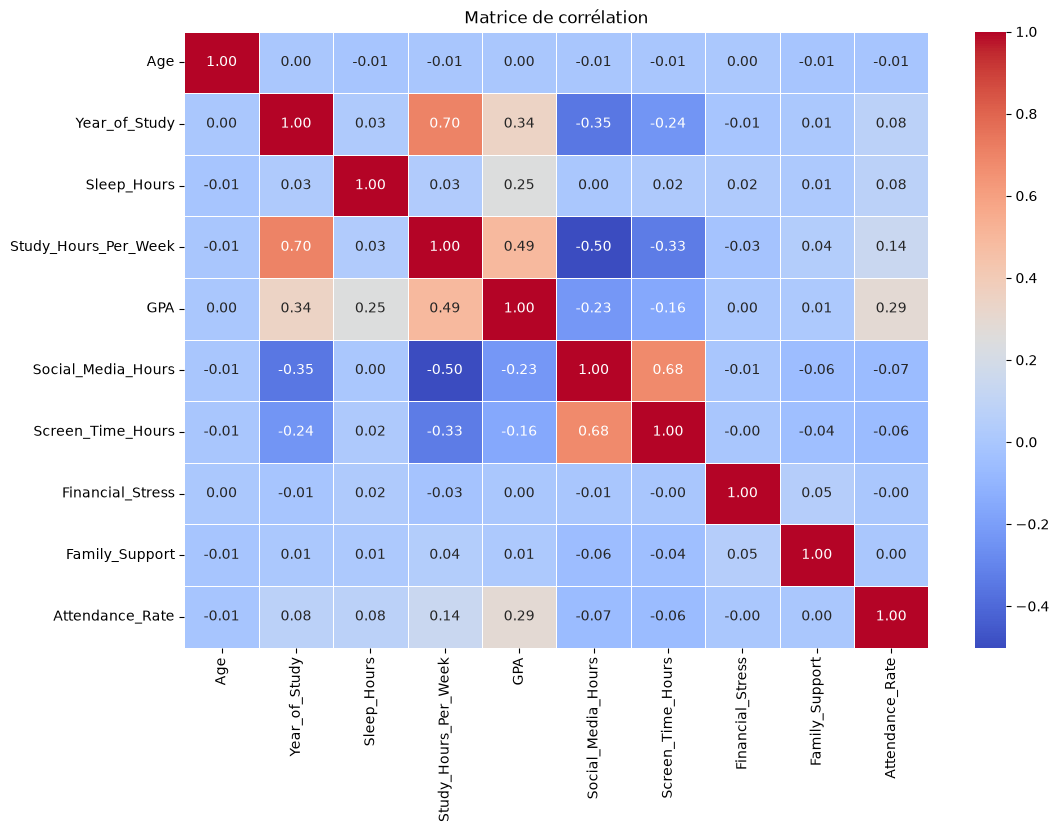

In [513]:
# Sélection des variables numériques
numeric_df = df.select_dtypes(include=np.number)

# Calcul des corrélations
corr_matrix = numeric_df.corr()

# Visualisation
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation")
plt.show()

### identifier les variables les plus fortement liées au niveau de risque ;


In [514]:
# from sklearn.feature_selection import f_classif

# # identifier les variables les plus fortement liées au niveau de risque
# target_col = "Mental_Health_Risk"

# # Variables explicatives (on exclut l'identifiant et la cible)
# X_fs = df.drop(columns=["Student_ID", target_col])
# y_fs = df[target_col]

# # Encodage des variables catégorielles
# X_fs = pd.get_dummies(X_fs, drop_first=True)

# # Remplacement des valeurs manquantes par la médiane
# X_fs = X_fs.fillna(X_fs.median())

# # Test ANOVA : F-score et p-value de chaque variable
# f_scores, p_values = f_classif(X_fs, y_fs)

# result = (
#     pd.DataFrame({
#         "Variable": X_fs.columns,
#         "F-score": f_scores,
#         "p-value": p_values
#     })
#     .sort_values("F-score", ascending=False)
#     .reset_index(drop=True)
# )

# display(result)

# # Visualisation des variables les plus fortement liées au risque
# plt.figure(figsize=(10, 6))
# sns.barplot(data=result.head(15), x="F-score", y="Variable")
# plt.title("Variables les plus fortement liées au niveau de risque")
# plt.xlabel("F-score (ANOVA)")
# plt.ylabel("Variable")
# plt.show()

In [515]:
# Remove the target column from X
X = df.drop(columns=['Student_ID', 'Mental_Health_Risk'])
y = df['Mental_Health_Risk']

## Étape 2 — Transformation et préparation des données

### Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).

In [516]:
# train_result = X_train[
#     X_train["Social_Media_Hours"] > X_train["Screen_Time_Hours"]
# ]

# test_result = X_test[
#     X_test["Social_Media_Hours"] > X_test["Screen_Time_Hours"]
# ]

# print("Train:", len(train_result))
# print("Test:", len(test_result))

# # Remove rows using their indexes
# X_train = X_train.drop(train_result.index)
# X_test = X_test.drop(test_result.index)

In [517]:
result = df[
    df["Social_Media_Hours"] > df["Screen_Time_Hours"]
]

print("Number of rows to remove:", len(result))

print(result[
    ["Social_Media_Hours", "Screen_Time_Hours"]
])

# Remove rows
df = df.drop(result.index)

print("Remaining rows:", len(df))

Number of rows to remove: 37
      Social_Media_Hours  Screen_Time_Hours
78                   5.0                4.9
168                  5.6                5.3
209                  7.5                7.3
278                  6.0                5.1
382                  5.3                4.1
424                  5.5                4.4
476                  5.5                5.3
505                  5.6                5.5
557                  4.6                4.4
588                  5.7                5.3
628                  4.9                4.6
641                  5.4                4.8
718                  6.2                5.9
758                  7.1                6.1
784                  7.9                6.9
942                  5.8                5.7
951                  5.4                5.2
956                  6.2                5.6
962                  7.0                6.3
980                  5.9                5.5
1166                 6.8                5.9
116

In [518]:
# Transformation et préparation des données

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2,stratify=y)


In [529]:
num_cols = [
    'Age',
    'Year_of_Study',
    'Sleep_Hours',
    'Study_Hours_Per_Week',
    'GPA',
    'Social_Media_Hours',
    'Screen_Time_Hours',
    'Financial_Stress',
    'Family_Support',
    'Attendance_Rate'
]

nominal_cols = [
    'Gender',
    'Part_Time_Job',
    'Previous_Mental_Health_History'
]

ordinal_cols = [
    'Physical_Activity',
    'Diet_Quality'
]
print(df[target_col].value_counts(dropna=False))

target_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
    }

df[target_col] = df[target_col].map(target_mapping)

Mental_Health_Risk
2.0    670
0.0    648
NaN    645
Name: count, dtype: int64


### Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée (IQR, Z-score, etc.).


In [520]:
# Select numerical columns
train_num = X_train[num_cols]
test_num = X_test[num_cols]

for col in num_cols:

    # Calculate IQR using Train
    Q1 = train_num[col].quantile(0.25)
    Q3 = train_num[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Extract Train outliers
    train_outliers = train_num.loc[
        (train_num[col] < lower) | (train_num[col] > upper), col
    ]

    # Extract Test outliers using Train boundaries
    test_outliers = test_num.loc[
        (test_num[col] < lower) | (test_num[col] > upper), col
    ]

    print(f"\n {col} ---->")
    print("lower : ",lower)
    print("upper : ",upper)
    print(f"Train: {len(train_outliers)} outliers")
    print(train_outliers.to_list())

    print(f"\nTest: {len(test_outliers)} outliers")
    print(test_outliers.to_list())

    


 Age ---->
lower :  15.5
upper :  27.5
Train: 2 outliers
[28, 28]

Test: 2 outliers
[29, 28]

 Year_of_Study ---->
lower :  -3.5
upper :  8.5
Train: 0 outliers
[]

Test: 0 outliers
[]

 Sleep_Hours ---->
lower :  3.75
upper :  9.75
Train: 9 outliers
[9.9, 9.9, 3.6, 10.0, 10.0, 10.0, 10.0, 3.7, 9.8]

Test: 3 outliers
[3.3, 10.0, 9.8]

 Study_Hours_Per_Week ---->
lower :  4.0
upper :  36.0
Train: 7 outliers
[3.2, 3.6, 38.3, 2.4, 2.7, 3.9, 37.5]

Test: 0 outliers
[]

 GPA ---->
lower :  1.5999999999999999
upper :  3.5199999999999996
Train: 5 outliers
[3.53, 1.5, 3.57, 3.66, 3.64]

Test: 1 outliers
[3.6]

 Social_Media_Hours ---->
lower :  3.05
upper :  9.05
Train: 10 outliers
[3.0, 10.0, 2.9, 2.1, 10.0, 9.4, 9.2, 9.5, 9.1, 9.3]

Test: 6 outliers
[2.4, 2.8, 9.4, 9.4, 2.4, 9.2]

 Screen_Time_Hours ---->
lower :  3.950000000000002
upper :  13.149999999999999
Train: 7 outliers
[13.6, 14.0, 3.8, 3.8, 3.4, 3.3, 3.8]

Test: 0 outliers
[]

 Financial_Stress ---->
lower :  0.14999999999999947
upp

In [521]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[
           
            ['Poor', 'Average', 'Good']
        ]
    ))
])

In [522]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('nominal', nominal_pipeline, nominal_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols)
])

In [523]:
model_SVC = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(probability=True,C=1, gamma='scale', kernel= 'linear'))
])

model_RF = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

model_GB = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [524]:
# OnHenc = OneHotEncoder(
#     handle_unknown='ignore',
#     sparse_output=False
# )

# encoded_data = OnHenc.fit_transform(df[categorial_nominal])

# encoded_df = pd.DataFrame(
#     encoded_data,
#     columns=OnHenc.get_feature_names_out(categorial_nominal),
#     index=df.index
# )

# print(encoded_df.head())


In [525]:
# encoder = OrdinalEncoder()

# df[categorial_Ordinal] = encoder.fit_transform(df[categorial_Ordinal])

# print(df[categorial_Ordinal].head())


Mental_Health_Risk
2.0    670
0.0    648
Name: count, dtype: int64
Mental_Health_Risk
2.0    50.834598
0.0    49.165402
Name: proportion, dtype: float64


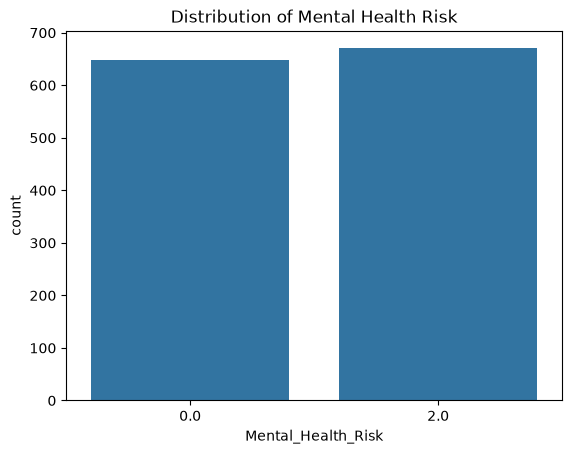

In [526]:
import matplotlib.pyplot as plt
import seaborn as sns

target_col = 'Mental_Health_Risk'

# Nombre d'observations par classe
print(df[target_col].value_counts())

# Pourcentage de chaque classe
print(df[target_col].value_counts(normalize=True) * 100)

# Visualisation
sns.countplot(data=df, x=target_col)
plt.title('Distribution of Mental Health Risk')
plt.show()


In [527]:
# scaler=StandardScaler()
# X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
# X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# X_train
df["Physical_Activity"].value_counts()


Physical_Activity
Moderate    883
Low         672
High        408
Name: count, dtype: int64

In [528]:
# Training
model_SVC.fit(X_train, y_train)

# Prediction
y_pred_svc = model_SVC.predict(X_test)

# Evaluation
print("SVC Accuracy:", accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

display(confusion_matrix(
    y_test, y_pred_svc,
    labels=['Low', 'Medium', 'High']
))

# ROC-AUC
y_prob_svc = model_SVC.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_prob_svc,
    multi_class='ovr',
    average='weighted',
    labels=model_SVC.classes_
)

print("ROC-AUC:", roc_auc)


ValueError: Shape mismatch: if categories is an array, it has to be of shape (n_features,).

In [ ]:
# Training
model_RF.fit(X_train, y_train)

# Prediction
y_pred_rf = model_RF.predict(X_test)

# Evaluation
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

display(confusion_matrix(y_test, y_pred_rf))

y_proba_rf = model_RF.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_proba_rf,
    multi_class='ovr',
    average='weighted',
    labels=model_RF.classes_
)

print("ROC-AUC:", roc_auc)


Random Forest Accuracy: 0.715
              precision    recall  f1-score   support

        High       0.75      0.79      0.77       136
         Low       0.80      0.78      0.79       132
      Medium       0.59      0.57      0.58       132

    accuracy                           0.71       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.71      0.71      0.71       400



array([[108,   1,  27],
       [  4, 103,  25],
       [ 32,  25,  75]])

ROC-AUC: 0.8542546500452284


In [ ]:
# Training
model_GB.fit(X_train, y_train)

# Prediction
y_pred_gb = model_GB.predict(X_test)

# Evaluation
print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))

print(classification_report(y_test, y_pred_gb))

display(confusion_matrix(y_test, y_pred_gb))

y_proba_gb = model_GB.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_proba_gb,
    multi_class='ovr',
    average='weighted',
    labels=model_GB.classes_
)

print("ROC-AUC:", roc_auc)


Gradient Boosting Accuracy: 0.725
              precision    recall  f1-score   support

        High       0.76      0.81      0.79       136
         Low       0.79      0.80      0.79       132
      Medium       0.61      0.56      0.58       132

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      0.72       400



array([[110,   2,  24],
       [  3, 106,  23],
       [ 31,  27,  74]])

ROC-AUC: 0.8823501809136138


In [ ]:
 
cv_results_SVC = cross_validate(
            model_SVC,
            X_train,
            y_train,
            cv=5,
            scoring='accuracy'
        )
print(cv_results_SVC['test_score'])
print("mean de test score : ",cv_results_SVC['test_score'].mean())


c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\skle

[0.753125 0.728125 0.73125  0.75     0.771875]
mean de test score :  0.7468750000000001


In [ ]:
cv_results_GB = cross_validate(
            model_GB,
            X_train,
            y_train,
            cv=5,
            scoring='accuracy'
        )
print(cv_results_GB['test_score'])
print("mean de test score : ",cv_results_GB['test_score'].mean())

[0.696875 0.70625  0.703125 0.65     0.721875]
mean de test score :  0.695625


In [ ]:
cv_results_RF = cross_validate(
            model_RF,
            X_train,
            y_train,
            cv=5,
            scoring='accuracy'
        )
print(cv_results_RF['test_score'])
print("mean de test score",cv_results_RF['test_score'].mean())

[0.65     0.684375 0.671875 0.66875  0.690625]
mean de test score 0.673125


In [ ]:
param_grid_svc = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}

grid_search_svc = GridSearchCV(
    estimator=model_SVC,
    param_grid=param_grid_svc,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search_svc.fit(X_train, y_train)
print("Best Parameters:", grid_search_svc.best_params_)
print("Best CV Accuracy:", grid_search_svc.best_score_)


Fitting 5 folds for each of 16 candidates, totalling 80 fits


c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV Accuracy: 0.7468750000000001


In [ ]:
param_grid_rf = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

grid_search_rf = GridSearchCV(
    estimator=model_RF,
    param_grid=param_grid_rf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV Accuracy:", grid_search_rf.best_score_)

best_model = grid_search_rf.best_estimator_

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


c:\Users\Youcode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters: {'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Best CV Accuracy: 0.694375


In [ ]:
param_grid_gb = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.01, 0.1, 0.2],
    "classifier__max_depth": [2, 3, 5],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}
grid_search_gb = GridSearchCV(
    estimator=model_GB,
    param_grid=param_grid_gb,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(X_train, y_train)
print("Best Parameters:", grid_search_gb.best_params_)
print("Best CV Score:", grid_search_gb.best_score_)

best_model = grid_search_gb.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters: {'classifier__learning_rate': 0.2, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV Score: 0.7037500000000001
